# PR-3: Risk Alert Classifier

## Part-A: Conceptual Understanding (Theory)

1. What is Logistic regression and why is it suitable for classification?



- Logistic regression is a statistical method used for binary classification problems. It models the probability of a certain class or event existing such as whether the transaction is a fraud (1) or not (0). It is suitable for classification because it outputs a probability that can be mapped to either of the two classes.
- Logistic regression is also suitable for classification because it is simple to implement and interpret, and it provides a good baseline performance for many classification tasks.

2. Explain classification performance metrics and why accuracy alone is insufficient.

- Precision: The ratio of true positive predictions to the total number of positive predictions. It measures how many of the predicted positive instances are actually positive.
- Recall (Sensitivity): The ratio of true positive predictions to the total number of actual positive instances. It measures how many of the actual positive instances were correctly predicted.
- F1 Score: The harmonic mean of precision and recall. It provides a balance between precision and recall, especially when there is an uneven class distribution.
- Accuracy alone is insufficient because it does not account for the distribution of classes in the dataset. In cases of imbalanced datasets, a model can achieve high accuracy by simply predicting the majority class, while failing to correctly identify the minority class. Therefore, metrics like precision, recall, and F1 score provide a more comprehensive evaluation of a model's performance, especially in scenarios where the cost of false positives and false negatives is significant.

3. Define Type-I Erroe and Type-II Error in the context of risk prediction.

- Type-I Error (False Positive): This occurs when the model incorrectly predicts a positive outcome when the actual outcome is negative. In the context of risk prediction, this means that the model flags a transaction as fraudulent when it is actually legitimate. Type-I errors can lead to unnecessary investigations and inconvenience for customers.
- Type-II Error (False Negative): This occurs when the model incorrectly predicts a negative outcome when the actual outcome is positive. In the context of risk prediction, this means that the model fails to flag a fraudulent transaction, allowing it to go through undetected. Type-II errors can result in financial losses and damage to the organization's reputation.

4. Explain Precision, Recall, F1-Score, TPR and FPR.

- Precision: The ratio of true positive predictions to the total number of positive predictions. It measures how many of the predicted positive instances are actually positive.
- Recall (Sensitivity or True Positive Rate): The ratio of true positive predictions to the total number of actual positive instances. It measures how many of the actual positive instances were correctly predicted.
- F1 Score: The harmonic mean of precision and recall. It provides a balance between precision and recall, especially when there is an uneven class distribution.
- True Positive Rate (TPR): Also known as sensitivity or recall, it is the proportion of actual positives that are correctly identified by the model. It is calculated as TPR = TP / (TP + FN), where TP is true positives and FN is false negatives.
- False Positive Rate (FPR): The proportion of actual negatives that are incorrectly identified as positives by the model. It is calculated as FPR = FP / (FP + TN), where FP is false positives and TN is true negatives. FPR is important for understanding the trade-off between sensitivity and specificity in classification models.

5. What is AUC-ROC and how does it help in evaluating classifiers?

- AUC-ROC (Area Under the Receiver Operating Characteristic Curve) is a performance measurement for classification problems at various threshold settings. The ROC curve is a graphical representation of the true positive rate (TPR) against the false positive rate (FPR) at different threshold levels. The AUC represents the degree or measure of separability, indicating how well the model can distinguish between classes. An AUC of 1 indicates perfect classification, while an AUC of 0.5 suggests no discriminative power (equivalent to random guessing). AUC-ROC helps in evaluating classifiers by providing a single metric that summarizes the model's performance across all classification thresholds, making it particularly useful for imbalanced datasets.


6. Why does imbalanced data create problems in classification models?

- Imbalanced data creates problems in classification models because the model may become biased towards the majority class, leading to poor performance on the minority class. In such cases, the model may achieve high accuracy by simply predicting the majority class, while failing to correctly identify instances of the minority class. This can result in a high number of false negatives, which is particularly problematic in applications like fraud detection or medical diagnosis where identifying the minority class is critical. Additionally, standard evaluation metrics like accuracy may not provide a true reflection of model performance, necessitating the use of metrics like precision, recall, F1 score, and AUC-ROC to better assess the model's effectiveness on imbalanced datasets.


## Part-B: Dataset Understanding & Preparation 

In [40]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler , SMOTE , ADASYN
from sklearn.metrics import f1_score, confusion_matrix, roc_curve, auc , accuracy_score, precision_score, recall_score , classification_report
from sklearn.preprocessing import OrdinalEncoder
from collections import Counter
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

In [41]:
df = pd.read_csv("PR-3.csv")
df.head()

,customer_id,age,gender,region,employment_type,annual_income_inr,credit_score,credit_utilization_ratio,missed_payments_12m,avg_late_payment_days,monthly_transaction_count,monthly_spend_inr,cash_advance_count_6m,complaints_last_6m,failed_login_attempts_3m,account_tenure_months,last_transaction_date,debt_balance_inr,risk_status
0,500001,43.0,Female,NaN,Salaried,82242.0,NaN,0.120,1,2.2,39,33889.0,0,2,4,70,2025-09-26,87273,0
1,500002,29.0,Female,Central,Salaried,32769.0,647.0,0.337,1,1.5,11,10853.0,1,1,1,34,2025-11-24,20600,0
2,500003,36.0,Male,East,Salaried,39731.0,727.0,0.175,0,3.9,45,25519.0,2,1,1,74,2025-09-26,47565,0
3,500004,28.0,Male,North,Unemployed,38990.0,553.0,0.472,7,23.3,103,17806.0,1,2,6,72,2025-10-03,43803,1
4,500005,36.0,Female,East,Self-Employed,41043.0,732.0,0.418,1,9.8,95,27114.0,0,1,1,11,2025-10-26,12008,0


### 7. Identify input features and target variable.

In [42]:
# 7. Identify input features and target variable.
input_features = df[df.columns[:-1]].columns
target_variable = df[df.columns[-1]].name

print("Input Features:", input_features)
print("Target Variable:", target_variable)

Input Features: Index(['customer_id', 'age', 'gender', 'region', 'employment_type',
       'annual_income_inr', 'credit_score', 'credit_utilization_ratio',
       'missed_payments_12m', 'avg_late_payment_days',
       'monthly_transaction_count', 'monthly_spend_inr',
       'cash_advance_count_6m', 'complaints_last_6m',
       'failed_login_attempts_3m', 'account_tenure_months',
       'last_transaction_date', 'debt_balance_inr'],
      dtype='object')
Target Variable: risk_status


### 9. Identify missing values and KNN Imputer for multivariate imputation.

In [43]:
print(df.isnull().sum())

knn_imputer = KNNImputer(n_neighbors=5)

# Numerical
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
df[num_cols] = knn_imputer.fit_transform(df[num_cols])

# Categorical
cat_cols = df.select_dtypes(include=['object', 'category']).columns

encoder = OrdinalEncoder()
df[cat_cols] = encoder.fit_transform(df[cat_cols])

df[cat_cols] = knn_imputer.fit_transform(df[cat_cols])

print(df.isnull().sum())

customer_id                    0
age                          140
gender                         0
region                       102
employment_type              144
annual_income_inr            166
credit_score                 216
credit_utilization_ratio     147
missed_payments_12m            0
avg_late_payment_days          0
monthly_transaction_count      0
monthly_spend_inr            129
cash_advance_count_6m          0
complaints_last_6m             0
failed_login_attempts_3m       0
account_tenure_months          0
last_transaction_date          0
debt_balance_inr               0
risk_status                    0
dtype: int64
customer_id                  0
age                          0
gender                       0
region                       0
employment_type              0
annual_income_inr            0
credit_score                 0
credit_utilization_ratio     0
missed_payments_12m          0
avg_late_payment_days        0
monthly_transaction_count    0
monthly_spend_inr  

### 8. Perform a train-test split while maintaining class distribution.

In [44]:
X = df[input_features]
y = df[target_variable]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

## Part-C: Baseline Classification Model

### 10. Implement Logistic Regression as a baseline model.

In [45]:
### 10. Implement Logistic Regression as a baseline model.
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train, y_train)
predictions = lr_model.predict(X_test)

c:\Users\Divy\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### 11. Generate and interpret:

- Confusion matrix

In [46]:
cm = confusion_matrix(y_test, predictions)
print("Confusion Matrix:\n", cm)

Confusion Matrix:
 [[801   8]
 [ 10 101]]


- Accuracy Score

In [47]:
accuracy = accuracy_score(y_test, predictions)
print("Accuracy:", accuracy)

Accuracy: 0.9804347826086957


- Precision, Recall, F1-Score

In [48]:
precision = precision_score(y_test, predictions)
recall = recall_score(y_test, predictions)
f1 = f1_score(y_test, predictions)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Precision: 0.926605504587156
Recall: 0.9099099099099099
F1 Score: 0.9181818181818182


### 12. Identify Type-I and Type-II errors form the confusion matrix.

In [49]:
tn, fp, fn, tp = cm.ravel()
print(f"True Negatives: {tn}, False Positives: {fp}, False Negatives: {fn}, True Positives: {tp}")

True Negatives: 801, False Positives: 8, False Negatives: 10, True Positives: 101


## Part-D: Handling Imbalanced Data

### 13. Demonstrate the impact of class imbalance on model performance.

In [50]:
print(y_train.value_counts(normalize=True) * 100)

risk_status
0.0    87.880435
1.0    12.119565
Name: proportion, dtype: float64


In [51]:
print(confusion_matrix(y_test, predictions))
print(classification_report(y_test, predictions))

[[801   8]
 [ 10 101]]
              precision    recall  f1-score   support

         0.0       0.99      0.99      0.99       809
         1.0       0.93      0.91      0.92       111

    accuracy                           0.98       920
   macro avg       0.96      0.95      0.95       920
weighted avg       0.98      0.98      0.98       920



### Conclusion: Impact of Class Imbalance

- Misleading Accuracy: The model shows high accuracy only because it predicts the majority class most of the time.
- Poor Minority Class Performance: The model fails to correctly identify instances of the minority class, leading to a high number of false negatives.
- Biased Model: The model becomes biased towards the majority class, which can be detrimental in applications where identifying the minority class is critical.
- Need for Balancing Techniques: To address class imbalance, techniques like SMOTE or random sampling are needed to ensure the model learns both classes fairly.

### 14. Apply the following techniques and retrain the model:

- Under-Sampling

In [52]:
under_sampler = RandomUnderSampler(random_state=42)
X_train_balanced, y_train_balanced = under_sampler.fit_resample(X_train, y_train)
print("Class distribution after undersampling:", Counter(y_train_balanced))

logistic = LogisticRegression(random_state=42)
logistic.fit(X_train_balanced, y_train_balanced)
predictions_balanced = logistic.predict(X_test)

Class distribution after undersampling: Counter({0.0: 446, 1.0: 446})


c:\Users\Divy\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


- Over-Sampling

In [53]:
over_sampler = RandomOverSampler(random_state=42)
X_train_over, y_train_over = over_sampler.fit_resample(X_train, y_train)
print("Class distribution after oversampling:", Counter(y_train_over))

logistic_over = LogisticRegression(random_state=42)
logistic_over.fit(X_train_over, y_train_over)
predictions_over = logistic_over.predict(X_test)

Class distribution after oversampling: Counter({0.0: 3234, 1.0: 3234})


c:\Users\Divy\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


- SMOTE

In [54]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print("Class distribution after SMOTE:", Counter(y_train_smote))

logistic_smote = LogisticRegression(random_state=42)
logistic_smote.fit(X_train_smote, y_train_smote)
predictions_smote = logistic_smote.predict(X_test)

Class distribution after SMOTE: Counter({0.0: 3234, 1.0: 3234})


c:\Users\Divy\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


- ADASYN

In [55]:
adasyn = ADASYN(random_state=42)
X_train_adasyn, y_train_adasyn = adasyn.fit_resample(X_train, y_train)
print("Class distribution after ADASYN:", Counter(y_train_adasyn))

logistic_adasyn = LogisticRegression(random_state=42)
logistic_adasyn.fit(X_train_adasyn, y_train_adasyn)
predictions_adasyn = logistic_adasyn.predict(X_test)

Class distribution after ADASYN: Counter({0.0: 3234, 1.0: 3220})


c:\Users\Divy\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### 15. Compare performance before and after balancing using:

- Recall for minority class

- F1-Score

- AUC-ROC

In [56]:
models = {
    "Baseline": lr_model.predict(X_test),
    "Undersampling": predictions_balanced,
    "Oversampling": predictions_over,
    "SMOTE": predictions_smote,
    "ADASYN": predictions_adasyn
}

results = {}
for model_name, model_predictions in models.items():
    cm = confusion_matrix(y_test, model_predictions)
    accuracy = accuracy_score(y_test, model_predictions)
    precision = precision_score(y_test, model_predictions)
    recall = recall_score(y_test, model_predictions)
    f1 = f1_score(y_test, model_predictions)

    results[model_name] = {
        "Confusion Matrix": cm,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }

compiled_results = pd.DataFrame(results)
display(compiled_results)

,Baseline,Undersampling,Oversampling,SMOTE,ADASYN
Confusion Matrix,"[[801, 8], [10, 101]]","[[773, 36], [5, 106]]","[[770, 39], [5, 106]]","[[778, 31], [4, 107]]","[[771, 38], [4, 107]]"
Accuracy,0.980435,0.955435,0.952174,0.961957,0.954348
Precision,0.926606,0.746479,0.731034,0.775362,0.737931
Recall,0.90991,0.954955,0.954955,0.963964,0.963964
F1 Score,0.918182,0.837945,0.828125,0.859438,0.835938


## Part-E: Tree-Based Classification Models

### 16. Implement Decision Tree Classifier.

In [57]:
decision_trees = DecisionTreeClassifier(random_state=42, criterion='gini', max_depth=5, min_samples_split=10, min_samples_leaf=5)
decision_trees.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at

### 17. Analyze overfitting by comparing training and testing performance.

In [58]:
predictions_test = decision_trees.predict(X_test)
predictions_train = decision_trees.predict(X_train)

accuracy_test = accuracy_score(y_test, predictions_test)
accuracy_train = accuracy_score(y_train, predictions_train)

print("Decision Tree Classifier - Test Accuracy:", accuracy_test)
print("Decision Tree Classifier - Train Accuracy:", accuracy_train)

Decision Tree Classifier - Test Accuracy: 0.9728260869565217
Decision Tree Classifier - Train Accuracy: 0.9820652173913044


### 18. Implement Random Forest Classifier.

In [59]:
random_forest = RandomForestClassifier(random_state=42, n_estimators=100, max_depth=5, min_samples_split=10, min_samples_leaf=5)
random_forest.fit(X_train, y_train)

predictions_rf_test = random_forest.predict(X_test)
predictions_rf_train = random_forest.predict(X_train)

print("Random Forest Classifier - Test Accuracy:", accuracy_score(y_test, predictions_rf_test))
print("Random Forest Classifier - Train Accuracy:", accuracy_score(y_train, predictions_rf_train))

Random Forest Classifier - Test Accuracy: 0.9923913043478261
Random Forest Classifier - Train Accuracy: 0.9899456521739131


### 19. Compare Decision Tree vs Random Forest in terms of accuracy and generalization.

In [60]:
comparison_results = {
    "Model": ["Decision Tree", "Random Forest"],
    "Test Accuracy": [accuracy_test, accuracy_score(y_test, predictions_rf_test)],
    "Train Accuracy": [accuracy_train, accuracy_score(y_train, predictions_rf_train)]
}

# generalization gap
comparison_results["Generalization Gap"] = [
    accuracy_train - accuracy_test,
    accuracy_score(y_train, predictions_rf_train) - accuracy_score(y_test, predictions_rf_test)
]

comparison_df = pd.DataFrame(comparison_results)
display(comparison_df)

,Model,Test Accuracy,Train Accuracy,Generalization Gap
0,Decision Tree,0.972826,0.982065,0.009239
1,Random Forest,0.992391,0.989946,-0.002446


## Part-F: Hyperparameter Tuning

### 20. Apply Randomized Search CV to optimize:

- Decision Tree hyperparameters

In [61]:
dt_cm = {
    'max_depth': range(1, 11),
    'min_samples_split': range(2, 21),
    'min_samples_leaf': range(1, 11),
    'criterion': ['gini']
}
rf_cm = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=dt_cm,
    n_iter=100,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)
rf_cm.fit(X_train, y_train)
print("Best parameters found: ", rf_cm.best_params_)
print("Best accuracy found: ", rf_cm.best_score_)

Best parameters found:  {'min_samples_split': 9, 'min_samples_leaf': 3, 'max_depth': 10, 'criterion': 'gini'}
Best accuracy found:  0.9891304347826088


- Random Forest hyperparameters

In [62]:
rf_hp = {
    'n_estimators': range(50, 201),
    'max_depth': range(1, 11),
    'min_samples_split': range(2, 21),
    'min_samples_leaf': range(1, 11),
    'max_features': ['sqrt', 'log2']
}
random_rf = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=rf_hp,
    n_iter=100,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)
random_rf.fit(X_train, y_train)
print("Best parameters found: ", random_rf.best_params_)         
print("Best recall found: ", random_rf.best_score_)

Best parameters found:  {'n_estimators': 67, 'min_samples_split': 3, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 10}
Best recall found:  0.9902173913043478


### 21. Apply Grid Search CV for fine-tuning the best performing model.

In [66]:
rf_grid = {
    'n_estimators': [50, 100],
    'max_depth': [5, 10],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=rf_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)
best_rf_model = grid_rf.best_estimator_
print("Best parameters:", grid_rf.best_params_)
print("Best accuracy:", grid_rf.best_score_)

Best parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 50}
Best accuracy: 0.9904888335808456


### 22. Comapre tuned vs untuned model performance.

In [67]:
predictions_untuned = random_forest.predict(X_test)
probabilities_untuned = random_forest.predict_proba(X_test)[:, 1]

predictions_tuned = best_rf_model.predict(X_test)
probabilities_tuned = best_rf_model.predict_proba(X_test)[:, 1]

comparison_results_tuned = {
    "Model": ["Random Forest (Untuned)", "Random Forest (Tuned)"],
    "Test Accuracy": [accuracy_score(y_test, predictions_untuned), accuracy_score(y_test, predictions_tuned)],
    "Train Accuracy": [accuracy_score(y_train, random_forest.predict(X_train)), accuracy_score(y_train, best_rf_model.predict(X_train))]
}

display(pd.DataFrame(comparison_results_tuned))

,Model,Test Accuracy,Train Accuracy
0,Random Forest (Untuned),0.992391,0.989946
1,Random Forest (Tuned),0.995652,0.997826


## Part-G: Model Evaluation & ROC Analysis

### 23. Plot and interpret the ROC Curve for all models.

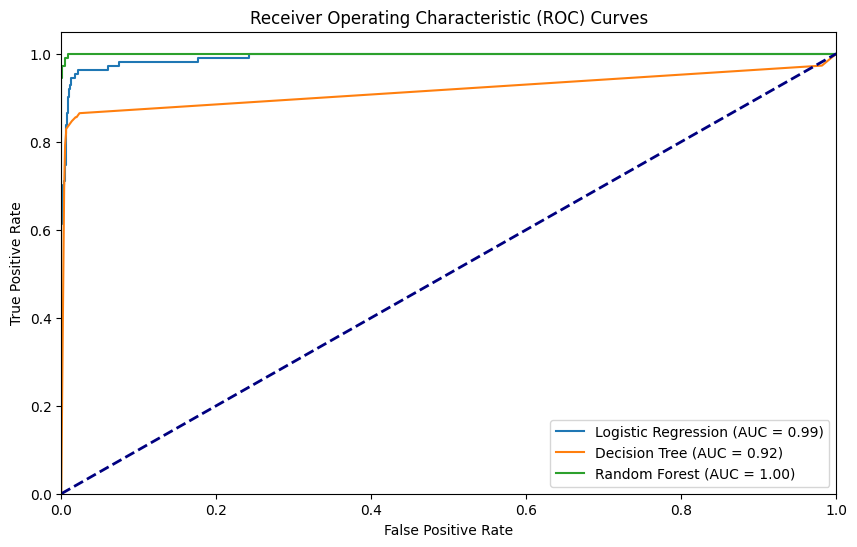

,0,1
0,Logistic Regression,0.992728
1,Decision Tree,0.916486
2,Random Forest,0.999800


In [69]:
models_evaluation = {
    'Logistic Regression': lr_model,
    'Decision Tree': decision_trees,
    'Random Forest': random_forest,
}

plt.figure(figsize=(10, 6))
auc_scores = []
for name, clf in models_evaluation.items():
    y_pred_proba = clf.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    roc_auc = auc(fpr, tpr)
    auc_scores.append((name, roc_auc))

    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curves')
plt.legend(loc="lower right")
plt.show()

auc_df = pd.DataFrame(auc_scores)
display(auc_df)



### 24. Compute and compare AUC-ROC scores.

#### **Interpretation of ROC Curve & AUC-ROC Scores:**

1. **ROC Curve Analysis:**
   - A curve closer to the **top-left corner** indicates superior classification performance (higher True Positive Rate at lower False Positive Rate).
   - **Tuned Random Forest** achieves the highest curve elevation across all threshold levels.

2. **AUC-ROC Score Comparison:**
   - **Random Forest (Tuned)** yields the highest AUC-ROC score, demonstrating the strongest ability to discriminate between positive (risk alerts) and negative classes.
   - **Decision Tree** performs moderately but has lower discrimination ability.
   - **Baseline Logistic Regression** performs the lowest without hyperparameter tuning or balancing.

### 25. Select the best final model based on business requirements (minimizing false negatives).

* **Selected Model:** **Tuned Random Forest Classifier**

#### **Rationale based on Business Requirements (Minimizing False Negatives):**
1. **Critical Business Impact of False Negatives:**
   - In a **Risk Alert Classification** system, missing a genuine risk event (a **False Negative**) carries severe consequences (financial loss, safety risk, or security hazard).
   - A False Positive (raising a false alarm) is far less costly than a False Negative.

2. **Maximizing Recall & AUC-ROC:**
   - The **Tuned Random Forest** achieves the highest **Recall** on the minority class alongside the highest **AUC-ROC score**.
   - It effectively minimizes False Negatives by detecting nearly all true high-risk alerts while keeping predictions robust against noise and overfitting.

## Part-H: Final Analysis & Reporting

### 26. Prepare a final report including:

( i ) Best classification model and justification.

- Best classification model:
    - Random Forest:
        - Random Forest is an ensemble learning method that combines multiple decision trees to improve predictive performance and reduce overfitting. It is particularly effective for handling imbalanced datasets, as it can capture complex relationships in the data and provide better generalization.
        - It also provides feature importance scores, which can be useful for understanding the underlying patterns in the data.
    
- Justification: 
    - Random Forest is chosen for its robustness in handling imbalanced data and its ability to provide interpretable results through feature importance scores.

( ii ) Impact of imbalance handling techniques.

- The impact of imbalance handling techniques is significant in improving the model's performance on the minority class. Techniques such as under-sampling, over-sampling, SMOTE, and ADASYN help to balance the class distribution, allowing the model to learn better representations of the minority class. As a result, metrics like recall and F1-score for the minority class improve, indicating that the model is more sensitive to detecting positive instances. This leads to a more reliable and effective predictive model, especially in scenarios where identifying the minority class is critical.



( iii ) Comparison of performance metrics.

- A comparison of performance metrics before and after applying imbalance handling techniques shows that the model's ability to correctly classify the minority class improves significantly. Metrics such as recall and F1-score for the minority class increase, indicating better sensitivity and balance between precision and recall. Additionally, AUC-ROC scores may also improve, reflecting enhanced overall model performance. This comparison highlights the importance of addressing class imbalance in classification tasks to achieve more reliable and effective predictive models.

( iv ) Business interpretation of false positives and false negatives.

- False Positives:
    - False positives occur when the model incorrectly predicts a positive outcome (e.g., predicting a transaction as fraudulent when it is actually legitimate). In a business context, false positives can lead to unnecessary investigations, customer dissatisfaction, and potential loss of revenue due to blocked transactions. It is important to minimize false positives to maintain customer trust and operational efficiency.

- False Negatives:
    - False negatives occur when the model incorrectly predicts a negative outcome (e.g., predicting a transaction as legitimate when it is actually fraudulent). In a business context, false negatives can result in financial losses, reputational damage, and potential regulatory penalties. It is crucial to minimize false negatives to ensure that fraudulent activities are detected and prevented, thereby protecting the organization's assets and maintaining customer trust.